In [1]:
from eyes import Eyes
import numpy as np

left_camera_id = 2
right_camera_id = 0

# Load the camera calibration
data = np.load('calibration/logitech_brio_100.npz')
camera_matrix = data['mtx']
dist_coeffs = data['dist']

R = np.array([[0, 0, 1], [0, 1, 0], [-1, 0, 0]])  # Rotation matrix
T = np.array([0.085, 0, 0])  # Translation vector

width = 640
height = 480

eyes_obj = Eyes(left_camera_id, right_camera_id, camera_matrix, dist_coeffs, R, T, width, height)
eyes_obj

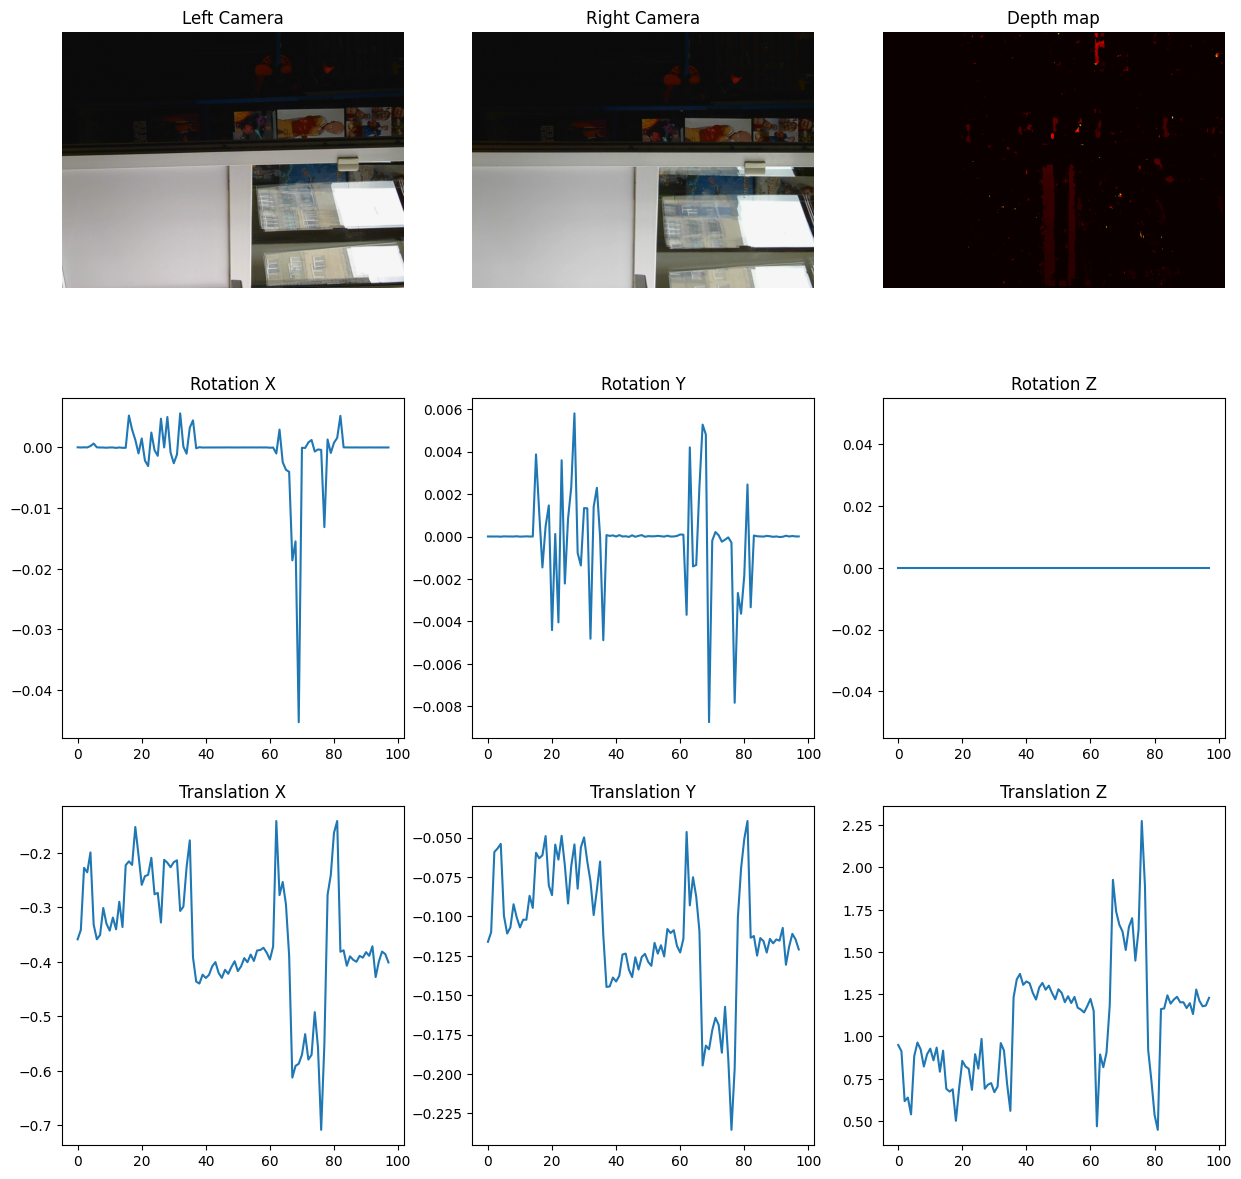

In [ ]:
from IPython.display import clear_output
import matplotlib.pyplot as plt
import cv2

rotation_x = []
rotation_y = []
rotation_z = []
translation_x = []
translation_y = []
translation_z = []

# Function to render images and disparity map
def render_frames(frame_left, frame_right, disparity, depth_map, rotation, translation):
    # Display frames and disparity map
    clear_output(wait=True)
    plt.figure(figsize=(15, 15))

    # Camera and depth views
    plt.subplot(3, 3, 1)
    plt.axis('off') 
    plt.title('Left Camera')
    plt.imshow(cv2.cvtColor(frame_left, cv2.COLOR_BGR2RGB))

    plt.subplot(3, 3, 2)
    plt.axis('off') 
    plt.title('Right Camera')
    plt.imshow(cv2.cvtColor(frame_right, cv2.COLOR_BGR2RGB))

    plt.subplot(3, 3, 3)
    plt.axis('off')
    plt.title('Depth map')
    plt.imshow(depth_map, cmap='hot')

    # Store rotation and translation values
    rotation_x.append(rotation[0])
    rotation_y.append(rotation[1]) 
    rotation_z.append(rotation[2])
    translation_x.append(translation[0])
    translation_y.append(translation[1])
    translation_z.append(translation[2])

    # Plot rotation components
    plt.subplot(3, 3, 4)
    plt.title('Rotation X')
    plt.plot(rotation_x)

    plt.subplot(3, 3, 5)
    plt.title('Rotation Y')
    plt.plot(rotation_y)

    plt.subplot(3, 3, 6)
    plt.title('Rotation Z')
    plt.plot(rotation_z)

    # Plot translation components
    plt.subplot(3, 3, 7)
    plt.title('Translation X')
    plt.plot(translation_x)

    plt.subplot(3, 3, 8)
    plt.title('Translation Y')
    plt.plot(translation_y)

    plt.subplot(3, 3, 9)
    plt.title('Translation Z')
    plt.plot(translation_z)

    plt.show()

eyes_obj.on_update_callback = render_frames

eyes_obj.start()

In [3]:
eyes_obj.release()